In [33]:
import requests
from astropy.io import fits
from PIL import Image
import numpy as np
from io import BytesIO
import matplotlib.pyplot as plt
import pandas as pd
import urllib.error

In [35]:
def get_fits_cutout_by_radec(ra, dec, cutout_size=101):
    url = 'https://www.lgacysurvey.org/viewer/cutout.fits?ra={}&dec={}&layer={}&pixscale={}&size={}&zoom=16'.format(ra, dec, 'ls-dr10-grz', 0.262, int(cutout_size))
    try:
        return(fits.open(url)[0].data)
    except Exception as e:
        print('ERROR: {}'.format(e))

def get_cutout_by_radec(ra, dec, cutout_size=101):
    ''' YMH+JI's addition to get cutout w/o target id -- 7/29/25 '''

    url = 'https://www.legacysurvey.org/viewer-desi/cutout.jpg?ra={}&dec={}&layer={}&pixscale={}&size={}&zoom=16'.format(ra, dec, 'ls-dr10-grz', 0.262, int(cutout_size))
    # response = requests.get(url)
    response = requests.get(url, auth=('desi', '[REDACTED]'))

    if response.status_code == 200:
        image_buffer = BytesIO(response.content)
        image = Image.open(image_buffer)
        return np.array(image)
    else:
        raise Exception(f"Failed to fetch image. Status code: {response.status_code}")
    

In [36]:
df = pd.read_csv('test_data/DR2_knowns copy_v36.csv')

In [37]:
for row_i, row in df.iterrows():
    if row_i < 10:
        ra,dec=row['Ra'], row['Dec']
        grz_arr = get_fits_cutout_by_radec(ra, dec)
        rgb_arr = get_cutout_by_radec(ra, dec)
        # np.save(f'test_data/{row_i}_grz.npy', grz_arr)
        # np.save(f'test_data/{row_i}_rgb.npy', rgb_arr)


ERROR: <urlopen error [Errno 8] nodename nor servname provided, or not known. requested URL: https://www.lgacysurvey.org/viewer/cutout.fits?ra=1.6798&dec=5.0237&layer=ls-dr10-grz&pixscale=0.262&size=101&zoom=16>
ERROR: <urlopen error [Errno 8] nodename nor servname provided, or not known. requested URL: https://www.lgacysurvey.org/viewer/cutout.fits?ra=1.7036&dec=-11.2181&layer=ls-dr10-grz&pixscale=0.262&size=101&zoom=16>
ERROR: <urlopen error [Errno 8] nodename nor servname provided, or not known. requested URL: https://www.lgacysurvey.org/viewer/cutout.fits?ra=4.093&dec=-9.1126&layer=ls-dr10-grz&pixscale=0.262&size=101&zoom=16>
ERROR: <urlopen error [Errno 8] nodename nor servname provided, or not known. requested URL: https://www.lgacysurvey.org/viewer/cutout.fits?ra=4.2156&dec=-5.8182&layer=ls-dr10-grz&pixscale=0.262&size=101&zoom=16>
ERROR: <urlopen error [Errno 8] nodename nor servname provided, or not known. requested URL: https://www.lgacysurvey.org/viewer/cutout.fits?ra=6.4448

In [25]:
grz_arr = np.load('test_data/0_grz.npy')
rgb_arr = np.load('test_data/0_rgb.npy')

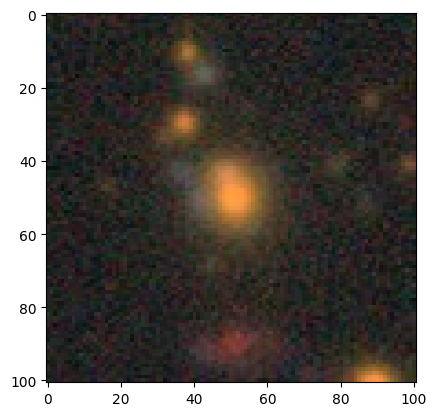

In [26]:
plt.imshow(rgb_arr)

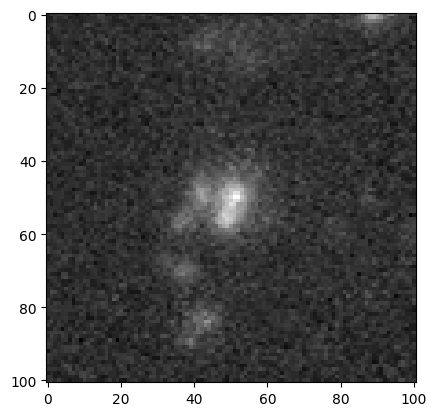

In [ ]:
plt.imshow(grz_arr[0],cmap='gray')

In [2]:
from Assets import InspectionSettings

In [6]:
Settings = InspectionSettings("JSON-for-settings-design-format.txt", "settings-state.txt")
Settings.tabs_names

['Grades and Comments', 'Quick Inspection']